# 01 - Data Inspection, Cleaning & Exploratory Data Analysis
**Telco Customer Churn** (IBM sample dataset, 7,043 customers of a fictional California telecom).

Goals of this notebook
1. Understand the data and its quality issues
2. Clean it (and identify columns that must **not** be used for prediction - data leakage)
3. Explore what is associated with churn, with statistical backing
4. Save the figures used in the README / report (`reports/figures/`)

> All numbers in the narrative are computed in code cells below - nothing is typed in by hand.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.metrics import roc_auc_score
from src import config as C
from src import plots as P
from src.data import load_raw, clean
P.set_style()
pd.set_option("display.max_columns", 50, "display.width", 140)
print("project root folder:", ROOT.name)

project root folder: telco-churn-prediction


## 1. Inspect the raw data

In [2]:
raw = load_raw()
print("shape:", raw.shape)
raw.head(3).T

shape: (7043, 33)


,0,1,2
CustomerID,3668-QPYBK,9237-HQITU,9305-CDSKC
Count,1,1,1
Country,United States,United States,United States
State,California,California,California
City,Los Angeles,Los Angeles,Los Angeles
Zip Code,90003,90005,90006
Lat Long,"33.964131, -118.272783","34.059281, -118.30742","34.048013, -118.293953"
Latitude,33.964131,34.059281,34.048013
Longitude,-118.272783,-118.30742,-118.293953
Gender,Male,Female,Female


In [3]:
info = pd.DataFrame({"dtype": raw.dtypes.astype(str), "n_unique": raw.nunique(), "n_missing": raw.isna().sum()})
info

,dtype,n_unique,n_missing
CustomerID,str,7043,0
Count,int64,1,0
Country,str,1,0
State,str,1,0
City,str,1129,0
Zip Code,int64,1652,0
Lat Long,str,1652,0
Latitude,float64,1652,0
Longitude,float64,1651,0
Gender,str,2,0


In [4]:
print("duplicate rows        :", raw.duplicated().sum())
print("duplicate CustomerID  :", raw["CustomerID"].duplicated().sum())
print("constant columns      :", [c for c in raw.columns if raw[c].nunique() == 1])
print("target distribution   :", raw["Churn Label"].value_counts().to_dict())

duplicate rows        : 0
duplicate CustomerID  : 0
constant columns      : ['Count', 'Country', 'State']
target distribution   : {'No': 5174, 'Yes': 1869}


### Data-quality findings
* No duplicates; `CustomerID` is unique.
* `Count`, `Country`, `State` are constants -> no information.
* `Total Charges` is stored as text because some rows are blank.
* `Churn Reason` is only filled for churners (so it is only known *after* churn).
* `Churn Label`, `Churn Value` are the target; `Churn Score` and `CLTV` are IBM-generated fields.

In [5]:
blank = raw[raw["Total Charges"].astype(str).str.strip() == ""]
print(len(blank), "blank Total Charges rows")
blank[["CustomerID", "Tenure Months", "Monthly Charges", "Total Charges", "Churn Label"]]

11 blank Total Charges rows


,CustomerID,Tenure Months,Monthly Charges,Total Charges,Churn Label
2234,4472-LVYGI,0,52.55,,No
2438,3115-CZMZD,0,20.25,,No
2568,5709-LVOEQ,0,80.85,,No
2667,4367-NUYAO,0,25.75,,No
2856,1371-DWPAZ,0,56.05,,No
4331,7644-OMVMY,0,19.85,,No
4687,3213-VVOLG,0,25.35,,No
5104,2520-SGTTA,0,20.00,,No
5719,2923-ARZLG,0,19.70,,No
6772,4075-WKNIU,0,73.35,,No


All blank rows have `Tenure Months = 0`: these are brand-new customers who have not been billed yet. Setting `Total Charges = 0` is the logically consistent fix (rather than dropping rows or imputing a mean).

## 2. Clean and check for leakage

In [6]:
df = clean(raw)
print(df.shape, "| total_charges dtype:", df["total_charges"].dtype, "| NaNs:", df["total_charges"].isna().sum())
leak = df.groupby("churn_label")[["churn_score", "cltv"]].mean().round(1)
leak

(7043, 34) | total_charges dtype: float64 | NaNs: 0


,churn_score,cltv
churn_label,,
No,50.1,4490.9
Yes,82.5,4149.4


In [7]:
auc_score = roc_auc_score(df["churn"], df["churn_score"])
print(f"Churn Score alone separates churners from non-churners with ROC-AUC = {auc_score:.3f}")
print("Churn Reason non-null only for churners:", df.loc[df.churn == 0, "churn_reason"].isna().all())

Churn Score alone separates churners from non-churners with ROC-AUC = 0.942
Churn Reason non-null only for churners: True


**Decision - columns excluded from the model**

| Column(s) | Reason |
|---|---|
| `churn_label`, `churn_value` | the target itself |
| `churn_score` | output of IBM's own churn model -> a single column gives AUC far above what's honest (shown above); would not exist for a genuinely new customer |
| `churn_reason` | recorded only after the customer has left |
| `cltv` | IBM-derived value estimate; kept out to stay conservative (an ablation in notebook 02 shows it adds nothing) |
| `customerid`, `count`, `country`, `state` | identifier / constants |
| `city`, `zip_code`, `lat_long`, `latitude`, `longitude` | high cardinality; ablation in notebook 02 shows negligible gain |
| `gender` | no association with churn (tested below) |

## 3. Target distribution and revenue at risk

In [8]:
churn_rate = df["churn"].mean()
rev = df.groupby("churn_label")["monthly_charges"].agg(["count", "sum", "mean"]).round(2)
rev["share_of_monthly_revenue_%"] = (rev["sum"] / rev["sum"].sum() * 100).round(1)
print(f"Overall churn rate: {churn_rate:.2%}  ({df.churn.sum()} of {len(df)} customers)")
rev

Overall churn rate: 26.54%  (1869 of 7043 customers)


,count,sum,mean,share_of_monthly_revenue_%
churn_label,,,,
No,5174,316985.75,61.27,69.5
Yes,1869,139130.85,74.44,30.5


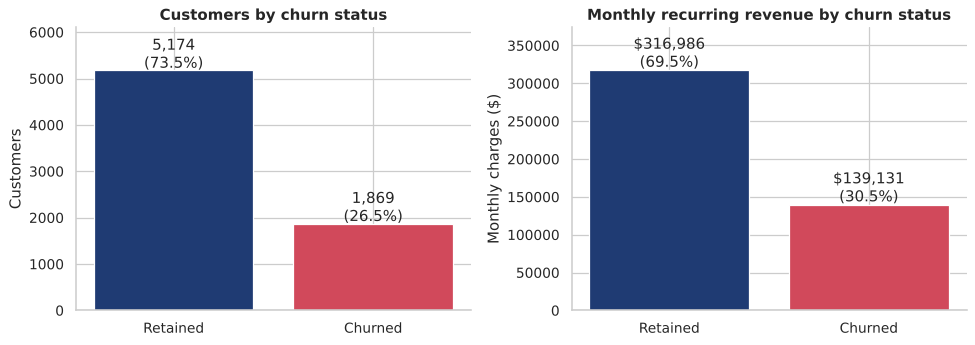

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
cnt = df["churn_label"].value_counts().reindex(["No", "Yes"])
ax[0].bar(["Retained", "Churned"], cnt.values, color=[P.NAVY, P.RED])
for i, v in enumerate(cnt.values):
    ax[0].text(i, v + 60, f"{v:,}\n({v/len(df):.1%})", ha="center")
ax[0].set(title="Customers by churn status", ylabel="Customers", ylim=(0, cnt.max() * 1.18))
mc = df.groupby("churn_label")["monthly_charges"].sum().reindex(["No", "Yes"])
ax[1].bar(["Retained", "Churned"], mc.values, color=[P.NAVY, P.RED])
for i, v in enumerate(mc.values):
    ax[1].text(i, v + 5000, f"${v:,.0f}\n({v/mc.sum():.1%})", ha="center")
ax[1].set(title="Monthly recurring revenue by churn status", ylabel="Monthly charges ($)", ylim=(0, mc.max() * 1.18))
fig.tight_layout(); _ = P.save(fig, "01_churn_distribution.png")

Roughly one in four customers churned - an **imbalanced** (but not extreme) problem, so accuracy alone would be misleading (a model that always predicts 'stay' would score ~73%). We will use ROC-AUC, PR-AUC, precision/recall and F1.

## 4. Numeric features vs churn

In [10]:
num = ["tenure_months", "monthly_charges", "total_charges"]
summ = df.groupby("churn_label")[num].agg(["mean", "median"]).round(1)
summ

tenure_months        monthly_charges        total_charges        
                     mean median            mean median          mean  median
churn_label                                                                  
No                   37.6   38.0            61.3   64.4        2549.9  1679.5
Yes                  18.0   10.0            74.4   79.6        1531.8   703.6

In [11]:
rows = []
for c in num:
    a, b = df.loc[df.churn == 1, c], df.loc[df.churn == 0, c]
    u = stats.mannwhitneyu(a, b)
    rows.append({"feature": c, "median_churned": a.median(), "median_retained": b.median(),
                 "mann_whitney_p": u.pvalue, "univariate_auc": roc_auc_score(df.churn, df[c])})
pd.DataFrame(rows).set_index("feature").round(4)

,median_churned,median_retained,mann_whitney_p,univariate_auc
feature,,,,
tenure_months,10.00,38.000,0.0,0.2601
monthly_charges,79.65,64.425,0.0,0.6208
total_charges,703.55,1679.525,0.0,0.3497


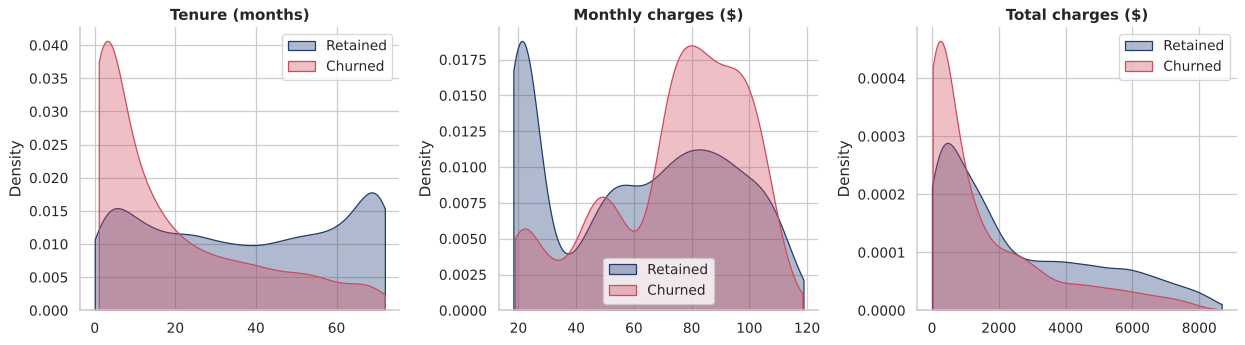

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
titles = {"tenure_months": "Tenure (months)", "monthly_charges": "Monthly charges ($)", "total_charges": "Total charges ($)"}
for a, c in zip(ax, num):
    for k, lab in [(0, "Retained"), (1, "Churned")]:
        sns.kdeplot(df.loc[df.churn == k, c], ax=a, fill=True, alpha=.35, color=P.CHURN_PAL[k], label=lab, cut=0)
    a.set(title=titles[c], xlabel="", ylabel="Density"); a.legend()
fig.tight_layout(); _ = P.save(fig, "02_numeric_distributions.png")

Churners have much **shorter tenure** and **higher monthly charges**; their total charges are lower simply because they stayed fewer months. Tenure is strongly right-skewed for churners (many leave in the first months).

## 5. Categorical features vs churn rate

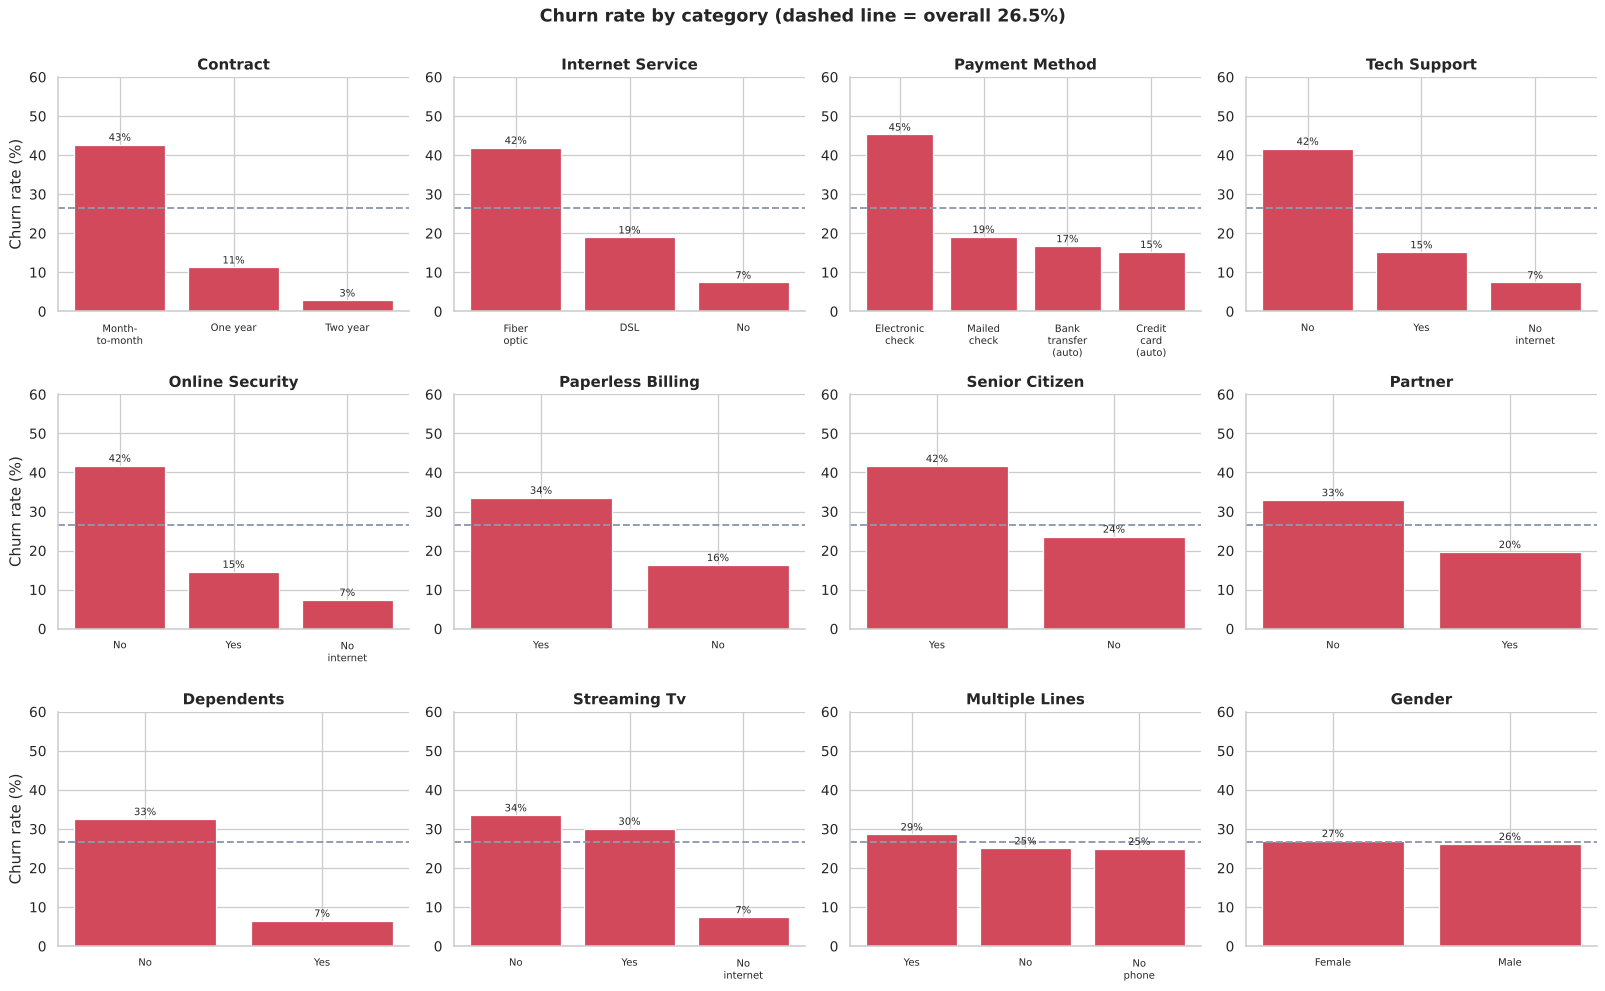

In [13]:
cats = ["contract", "internet_service", "payment_method", "tech_support", "online_security", "paperless_billing",
        "senior_citizen", "partner", "dependents", "streaming_tv", "multiple_lines", "gender"]
d = df.copy()
d["senior_citizen"] = d["senior_citizen"].map({0: "No", 1: "Yes"})
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for a, c in zip(axes.ravel(), cats):
    g = d.groupby(c)["churn"].agg(["mean", "size"]).sort_values("mean", ascending=False)
    a.bar(range(len(g)), g["mean"] * 100, color=P.RED)
    a.axhline(churn_rate * 100, ls="--", color=P.GREY)
    a.set_xticks(range(len(g))); a.set_xticklabels([s.replace(" (automatic)", "\n(auto)").replace("No internet service", "No\ninternet").replace("Month-to-month", "Month-\nto-month").replace("Bank transfer", "Bank\ntransfer").replace("Credit card", "Credit\ncard").replace("Electronic check", "Electronic\ncheck").replace("Mailed check", "Mailed\ncheck").replace("No phone service", "No\nphone").replace("Fiber optic", "Fiber\noptic") for s in g.index], fontsize=8)
    for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
        a.text(i, m * 100 + 1, f"{m*100:.0f}%", ha="center", fontsize=8)
    a.set(title=c.replace("_", " ").title(), ylim=(0, 60), ylabel="Churn rate (%)" if a in axes[:, 0] else "")
fig.suptitle(f"Churn rate by category (dashed line = overall {churn_rate:.1%})", fontsize=14, fontweight="bold", y=1.0)
fig.tight_layout(); _ = P.save(fig, "03_churn_rate_by_category.png")

In [14]:
def rate(col):
    return (df.groupby(col)["churn"].agg(rate="mean", customers="size").assign(rate=lambda x: (x.rate * 100).round(1)))
for c in ["contract", "internet_service", "payment_method", "tech_support", "paperless_billing"]:
    print(rate(c), "\n")

                rate  customers
contract                       
Month-to-month  42.7       3875
One year        11.3       1473
Two year         2.8       1695 

                  rate  customers
internet_service                 
DSL               19.0       2421
Fiber optic       41.9       3096
No                 7.4       1526 

                           rate  customers
payment_method                            
Bank transfer (automatic)  16.7       1544
Credit card (automatic)    15.2       1522
Electronic check           45.3       2365
Mailed check               19.1       1612 

                     rate  customers
tech_support                        
No                   41.6       3473
No internet service   7.4       1526
Yes                  15.2       2044 

                   rate  customers
paperless_billing                 
No                 16.3       2872
Yes                33.6       4171 



## 6. Tenure x contract - the strongest interaction

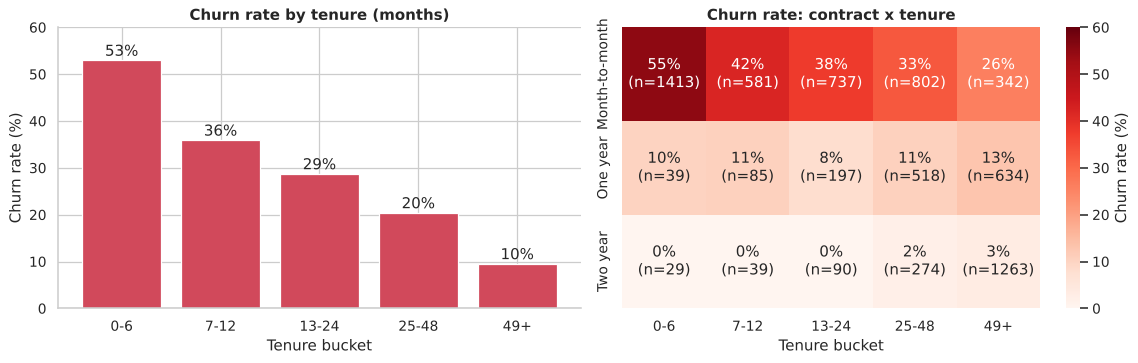

tenure_bucket,0-6,7-12,13-24,25-48,49+
contract,,,,,
Month-to-month,55.2,42.0,37.7,32.9,26.0
One year,10.3,10.6,8.1,10.6,12.9
Two year,0.0,0.0,0.0,2.2,3.3


In [15]:
d = df.copy()
d["tenure_bucket"] = pd.cut(d.tenure_months, [-1, 6, 12, 24, 48, np.inf], labels=["0-6", "7-12", "13-24", "25-48", "49+"])
piv = d.pivot_table(index="contract", columns="tenure_bucket", values="churn", aggfunc="mean", observed=True) * 100
cnt = d.pivot_table(index="contract", columns="tenure_bucket", values="churn", aggfunc="size", observed=True)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
by = d.groupby("tenure_bucket", observed=True)["churn"].mean() * 100
ax[0].bar(by.index.astype(str), by.values, color=P.RED)
for i, v in enumerate(by.values): ax[0].text(i, v + 1, f"{v:.0f}%", ha="center")
ax[0].set(title="Churn rate by tenure (months)", xlabel="Tenure bucket", ylabel="Churn rate (%)", ylim=(0, 60))
annot = piv.round(0).astype("Int64").astype(str) + "%\n(n=" + cnt.astype(str) + ")"
sns.heatmap(piv, annot=annot.values, fmt="", cmap="Reds", cbar_kws={"label": "Churn rate (%)"}, ax=ax[1], vmin=0, vmax=60)
ax[1].set(title="Churn rate: contract x tenure", xlabel="Tenure bucket", ylabel="")
fig.tight_layout(); _ = P.save(fig, "04_tenure_contract.png")
piv.round(1)

## 7. Internet service, support add-ons and price

internet_service
DSL            58.1
Fiber optic    91.5


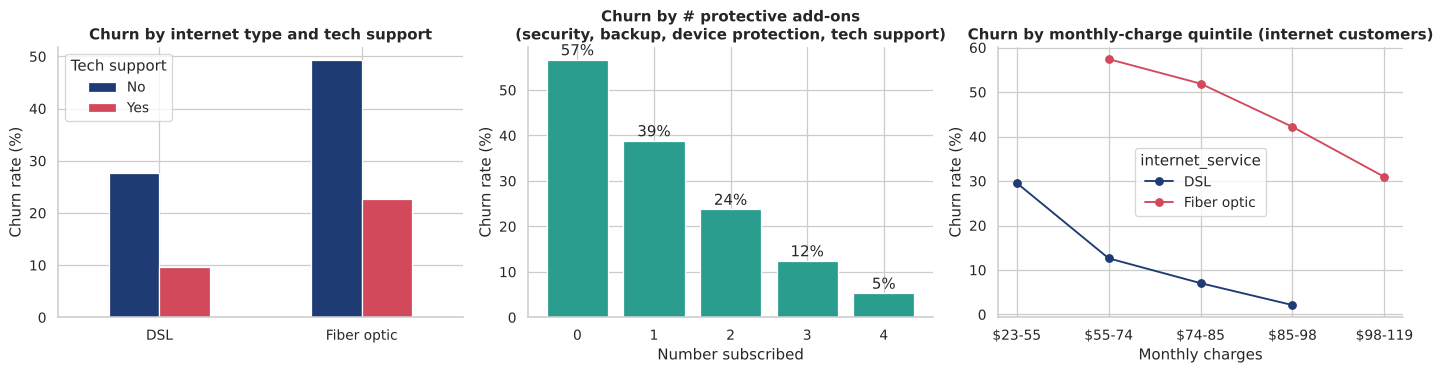

In [16]:
d = df[df.internet_service != "No"].copy()
d["n_addons"] = (d[["online_security", "online_backup", "device_protection", "tech_support", "streaming_tv", "streaming_movies"]] == "Yes").sum(axis=1)
d["n_protective"] = (d[["online_security", "online_backup", "device_protection", "tech_support"]] == "Yes").sum(axis=1)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
g = d.groupby(["internet_service", "tech_support"])["churn"].mean().unstack() * 100
g.plot.bar(ax=ax[0], color=[P.NAVY, P.RED], rot=0)
ax[0].set(title="Churn by internet type and tech support", xlabel="", ylabel="Churn rate (%)"); ax[0].legend(title="Tech support")
g2 = d.groupby("n_protective")["churn"].mean() * 100
ax[1].bar(g2.index, g2.values, color=P.TEAL)
for i, v in zip(g2.index, g2.values): ax[1].text(i, v + 1, f"{v:.0f}%", ha="center")
ax[1].set(title="Churn by # protective add-ons\n(security, backup, device protection, tech support)", xlabel="Number subscribed", ylabel="Churn rate (%)")
d["charge_band"] = pd.qcut(d.monthly_charges, 5)
g3 = d.groupby(["charge_band", "internet_service"], observed=True)["churn"].mean().unstack() * 100
g3.index = [f"${i.left:.0f}-{i.right:.0f}" for i in g3.index]
g3.plot(ax=ax[2], marker="o", color=[P.NAVY, P.RED]); ax[2].set(title="Churn by monthly-charge quintile (internet customers)", xlabel="Monthly charges", ylabel="Churn rate (%)")
fig.tight_layout(); _ = P.save(fig, "05_internet_services.png")
print(d.groupby("internet_service")["monthly_charges"].mean().round(2).to_string())

## 8. Strength of association with churn (statistical tests)

In [17]:
def cramers_v(x, y):
    t = pd.crosstab(x, y); chi2, p, dof, _ = stats.chi2_contingency(t)
    return np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1))), p
cat_cols = ["contract", "internet_service", "payment_method", "tech_support", "online_security", "online_backup",
            "device_protection", "paperless_billing", "senior_citizen", "partner", "dependents", "streaming_tv",
            "streaming_movies", "multiple_lines", "phone_service", "gender"]
rows = [dict(feature=c, cramers_v=cramers_v(df[c], df.churn)[0], chi2_p=cramers_v(df[c], df.churn)[1]) for c in cat_cols]
assoc = pd.DataFrame(rows).set_index("feature").sort_values("cramers_v", ascending=False)
assoc["significant_at_0.05"] = assoc.chi2_p < 0.05
assoc.to_csv(C.METRICS_DIR / "eda_association.csv")
assoc.round(4)

,cramers_v,chi2_p,significant_at_0.05
feature,,,
contract,0.4101,0.0000,True
online_security,0.3474,0.0000,True
tech_support,0.3429,0.0000,True
internet_service,0.3225,0.0000,True
payment_method,0.3034,0.0000,True
online_backup,0.2923,0.0000,True
device_protection,0.2816,0.0000,True
dependents,0.2482,0.0000,True
streaming_movies,0.2310,0.0000,True


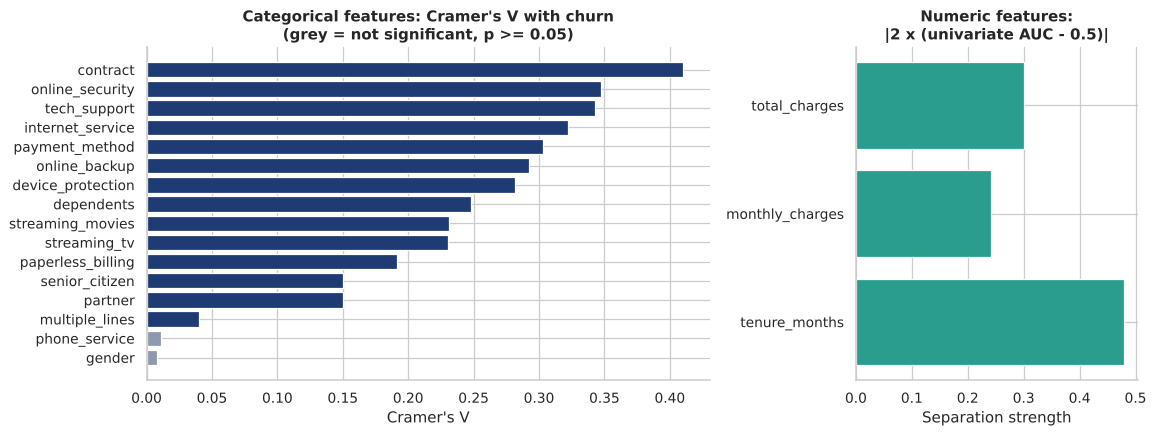

In [18]:
num_auc = pd.Series({c: roc_auc_score(df.churn, df[c]) for c in num})
fig, ax = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [2, 1]})
a = assoc["cramers_v"].sort_values()
ax[0].barh(a.index, a.values, color=[P.GREY if not assoc.loc[i, "significant_at_0.05"] else P.NAVY for i in a.index])
ax[0].set(title="Categorical features: Cramer's V with churn\n(grey = not significant, p >= 0.05)", xlabel="Cramer's V")
ax[1].barh(num_auc.index, (num_auc - .5).abs() * 2, color=P.TEAL)
ax[1].set(title="Numeric features:\n|2 x (univariate AUC - 0.5)|", xlabel="Separation strength")
fig.tight_layout(); _ = P.save(fig, "06_association_strength.png")

`gender` (and `phone_service`) show no statistically significant association with churn; contract type, tenure, internet service type and payment method are the strongest signals. This supports excluding `gender` from the model.

## 9. Why do customers say they left? (post-hoc, descriptive only)

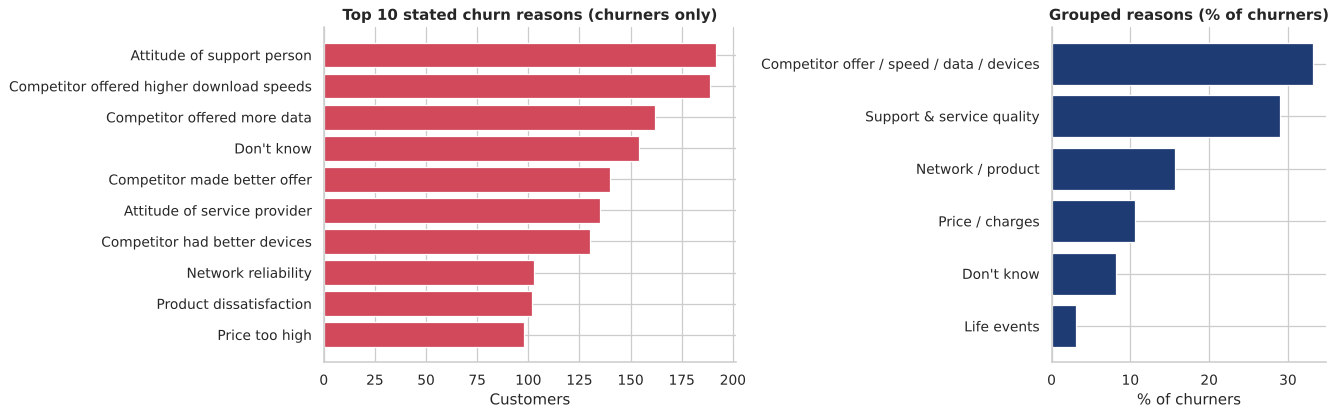

reason_group
Competitor offer / speed / data / devices    33.2
Support & service quality                    29.1
Network / product                            15.7
Price / charges                              10.6
Don't know                                    8.2
Life events                                   3.2
Name: count, dtype: float64

In [19]:
ch = df[df.churn == 1].copy()
GROUPS = {
    "Competitor offer / speed / data / devices": ["Competitor made better offer", "Competitor offered higher download speeds", "Competitor offered more data", "Competitor had better devices"],
    "Support & service quality": ["Attitude of support person", "Attitude of service provider", "Poor expertise of phone support", "Poor expertise of online support", "Lack of self-service on Website", "Service dissatisfaction"],
    "Network / product": ["Network reliability", "Product dissatisfaction", "Limited range of services", "Lack of affordable download/upload speed"],
    "Price / charges": ["Price too high", "Extra data charges", "Long distance charges"],
    "Life events": ["Moved", "Deceased"],
    "Don't know": ["Don't know"],
}
LOOKUP = {r: g for g, rs in GROUPS.items() for r in rs}
assert set(df.loc[df.churn == 1, "churn_reason"]) <= set(LOOKUP), "unmapped churn reason"
ch["reason_group"] = ch["churn_reason"].map(LOOKUP)
rg = ch["reason_group"].value_counts()
top = ch["churn_reason"].value_counts().head(10)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})
ax[0].barh(top.index[::-1], top.values[::-1], color=P.RED); ax[0].set(title="Top 10 stated churn reasons (churners only)", xlabel="Customers")
ax[1].barh(rg.index[::-1], (rg / rg.sum() * 100).values[::-1], color=P.NAVY); ax[1].set(title="Grouped reasons (% of churners)", xlabel="% of churners")
fig.tight_layout(); _ = P.save(fig, "07_churn_reasons.png")
(rg / rg.sum() * 100).round(1)

*Churn reasons are recorded after the customer leaves, so they are used for business interpretation only - never as a model feature. The grouping into six themes is my own manual mapping of the 20 reason labels (see `GROUPS` above).*

## 10. High-risk vs low-risk customer segments

In [20]:
d = df.copy()
seg = {
 "Month-to-month + Fiber + no tech support + tenure <= 12m": (d.contract == "Month-to-month") & (d.internet_service == "Fiber optic") & (d.tech_support == "No") & (d.tenure_months <= 12),
 "Month-to-month (all)": d.contract == "Month-to-month",
 "Electronic check (all)": d.payment_method == "Electronic check",
 "One/two-year contract (all)": d.contract != "Month-to-month",
 "Two-year contract + tenure > 24m": (d.contract == "Two year") & (d.tenure_months > 24),
}
out = pd.DataFrame({k: {"customers": int(m.sum()), "share_of_base_%": m.mean() * 100, "churn_rate_%": d.loc[m, "churn"].mean() * 100,
                        "share_of_all_churners_%": d.loc[m, "churn"].sum() / d.churn.sum() * 100, "avg_monthly_$": d.loc[m, "monthly_charges"].mean()}
                    for k, m in seg.items()}).T.round(1)
out.to_csv(C.METRICS_DIR / "eda_segments.csv")
out

,customers,share_of_base_%,churn_rate_%,share_of_all_churners_%,avg_monthly_$
Month-to-month + Fiber + no tech support + tenure <= 12m,833.0,11.8,71.1,31.7,81.2
Month-to-month (all),3875.0,55.0,42.7,88.6,66.4
Electronic check (all),2365.0,33.6,45.3,57.3,76.3
One/two-year contract (all),3168.0,45.0,6.8,11.4,62.8
Two-year contract + tenure > 24m,1537.0,21.8,3.1,2.6,63.8


## 11. Key findings (computed)

In [21]:
g = lambda c, v: df.loc[df[c] == v, "churn"].mean() * 100
m2m, two = g("contract", "Month-to-month"), g("contract", "Two year")
print(f"1. Overall churn: {churn_rate:.1%}. Churned customers = {rev.loc['Yes','share_of_monthly_revenue_%']:.1f}% of monthly revenue.")
print(f"2. Contract: month-to-month {m2m:.1f}% vs one-year {g('contract','One year'):.1f}% vs two-year {two:.1f}%.")
print(f"3. Tenure: median {df.loc[df.churn==1,'tenure_months'].median():.0f} months for churners vs {df.loc[df.churn==0,'tenure_months'].median():.0f} for retained; first-6-month churn = {df.loc[df.tenure_months<=6,'churn'].mean()*100:.1f}%.")
print(f"4. Internet: fiber {g('internet_service','Fiber optic'):.1f}% vs DSL {g('internet_service','DSL'):.1f}% vs none {g('internet_service','No'):.1f}%.")
print(f"5. Payment: electronic check {g('payment_method','Electronic check'):.1f}% vs automatic bank/card {df.loc[df.payment_method.str.contains('automatic'),'churn'].mean()*100:.1f}%.")
print(f"6. Tech support: no {g('tech_support','No'):.1f}% vs yes {g('tech_support','Yes'):.1f}%. Online security: no {g('online_security','No'):.1f}% vs yes {g('online_security','Yes'):.1f}%.")
print(f"7. Gender is not associated with churn (Cramer's V={assoc.loc['gender','cramers_v']:.3f}, p={assoc.loc['gender','chi2_p']:.2f}).")
print(f"8. Seniors churn {df.loc[df.senior_citizen==1,'churn'].mean()*100:.1f}% vs {df.loc[df.senior_citizen==0,'churn'].mean()*100:.1f}% for non-seniors.")

1. Overall churn: 26.5%. Churned customers = 30.5% of monthly revenue.
2. Contract: month-to-month 42.7% vs one-year 11.3% vs two-year 2.8%.
3. Tenure: median 10 months for churners vs 38 for retained; first-6-month churn = 52.9%.
4. Internet: fiber 41.9% vs DSL 19.0% vs none 7.4%.
5. Payment: electronic check 45.3% vs automatic bank/card 16.0%.
6. Tech support: no 41.6% vs yes 15.2%. Online security: no 41.8% vs yes 14.6%.
7. Gender is not associated with churn (Cramer's V=0.008, p=0.49).
8. Seniors churn 41.7% vs 23.6% for non-seniors.


### Caveats
* These are **associations**, not causal effects - e.g. fiber customers also pay more, and may be more price-sensitive or have different competitor options.
* Univariate rates can overlap (month-to-month customers are also shorter-tenure); the model in notebook 02 helps separate effects.
* One snapshot of one (synthetic-style) California dataset: no time dimension, so we cannot study when offers/price changes happened.